In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Chest X-ray Classification using Deep Learning

## Introduction
Chest X-ray imaging is a crucial diagnostic tool for classifying the pneumonia disease. This project aims to develop a deep learning model for automated classification of chest X-ray images, enhancing the efficiency and accuracy of medical diagnosis.


In [ ]:
import os

path = "/kaggle/input/chestxrayfinal/chest_xray"
folders = [f for f in os.listdir(path) if os.path.isdir(os.path.join(path, f))]

print("Number of folders:", len(folders))
print("Folders:", folders)


Number of folders: 2
Folders: ['PNEUMONIA', 'NORMAL']


## Dataset Description
The dataset consists of labeled chest X-ray images. The images are categorized into two classes, including Normal and Pneumonia. The dataset contains:

- **Total Images:** 5856
- **Categories:** Normal, Pneumonia
- **Image Format:** JPEG


In [ ]:
for folder in folders:
    folder_path = os.path.join(path, folder)
    num_images = len(os.listdir(folder_path))
    print(f"{folder}: {num_images} images")


PNEUMONIA: 4273 images
NORMAL: 1583 images


### Data Modification  
To improve classification granularity, we are further dividing the **Pneumonia** category into:  
- **Bacterial Pneumonia:** X-rays showing bacterial lung infections.  
- **Viral Pneumonia:** X-rays indicating viral lung infections.  

This modification transforms the dataset into a three-class classification problem:  
- **Normal**  
- **Bacterial Pneumonia**  
- **Viral Pneumonia**  

This refinement allows the model to distinguish between different types of pneumonia, potentially aiding more precise diagnosis.

In [ ]:
import os
import shutil

# Define paths
pneumonia_path = "/kaggle/input/chestxrayfinal/chest_xray/PNEUMONIA"
output_viral = "/kaggle/working/PNEUMONIA_VIRAL"
output_bacterial = "/kaggle/working/PNEUMONIA_BACTERIAL"

# Create new folders
os.makedirs(output_viral, exist_ok=True)
os.makedirs(output_bacterial, exist_ok=True)

# Iterate through images
for image in os.listdir(pneumonia_path):
    image_path = os.path.join(pneumonia_path, image)

    if "virus" in image.lower():
        shutil.copy(image_path, os.path.join(output_viral, image))
    elif "bacteria" in image.lower():
        shutil.copy(image_path, os.path.join(output_bacterial, image))

print("Images separated successfully!")


Images separated successfully!


In [ ]:
print("Viral Pneumonia:", len(os.listdir(output_viral)))
print("Bacterial Pneumonia:", len(os.listdir(output_bacterial)))


Viral Pneumonia: 1493
Bacterial Pneumonia: 2780


In [ ]:
import shutil

# Define source and destination paths
normal_path = "/kaggle/input/chestxrayfinal/chest_xray/NORMAL"
output_normal = "/kaggle/working/NORMAL"

# Create the destination folder
os.makedirs(output_normal, exist_ok=True)

# Copy images
for image in os.listdir(normal_path):
    shutil.copy(os.path.join(normal_path, image), os.path.join(output_normal, image))

print("Normal images copied successfully!")


Normal images copied successfully!


## Class Imbalance in the Dataset  
After modifying the dataset to include three categories, we observed an imbalance in the distribution of classes:  

- **Bacterial Pneumonia:** 2,780 images  
- **Viral Pneumonia:** 1,493 images  
- **Normal:** 1,583 images  


In [ ]:
# Define paths
output_normal = "/kaggle/working/NORMAL"
output_viral = "/kaggle/working/PNEUMONIA_VIRAL"
output_bacterial = "/kaggle/working/PNEUMONIA_BACTERIAL"

# Count images in each folder
num_normal = len(os.listdir(output_normal))
num_viral = len(os.listdir(output_viral))
num_bacterial = len(os.listdir(output_bacterial))

# Print results
print(f"Normal Images: {num_normal}")
print(f"Viral Pneumonia Images: {num_viral}")
print(f"Bacterial Pneumonia Images: {num_bacterial}")


Normal Images: 1583
Viral Pneumonia Images: 1493
Bacterial Pneumonia Images: 2780


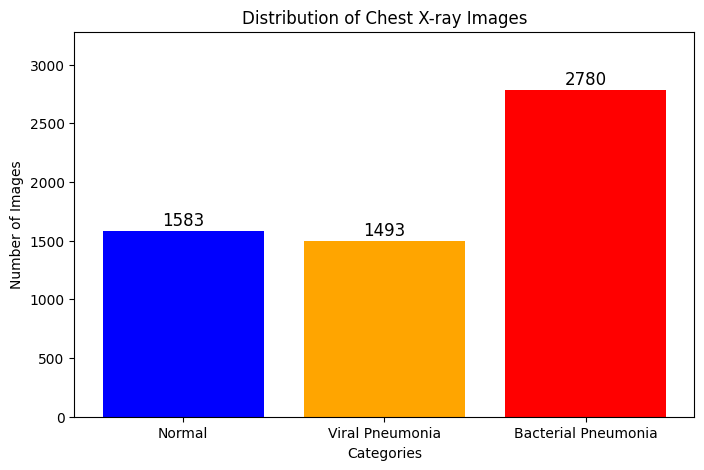

In [ ]:
import matplotlib.pyplot as plt

# Data
categories = ["Normal", "Viral Pneumonia", "Bacterial Pneumonia"]
counts = [1583, 1493, 2780]

# Plot
plt.figure(figsize=(8, 5))
plt.bar(categories, counts, color=['blue', 'orange', 'red'])
plt.xlabel("Categories")
plt.ylabel("Number of Images")
plt.title("Distribution of Chest X-ray Images")
plt.ylim(0, max(counts) + 500)  # Adjust y-axis for better visibility

# Show values on bars
for i, count in enumerate(counts):
    plt.text(i, count + 50, str(count), ha='center', fontsize=12)

plt.show()


SAMPLE IMAGES OF TYPE NORMAL ,PNEUMONIA_VIRAL AND PNEUMONIA_BACTERIAL #

Original NORMAL Images:


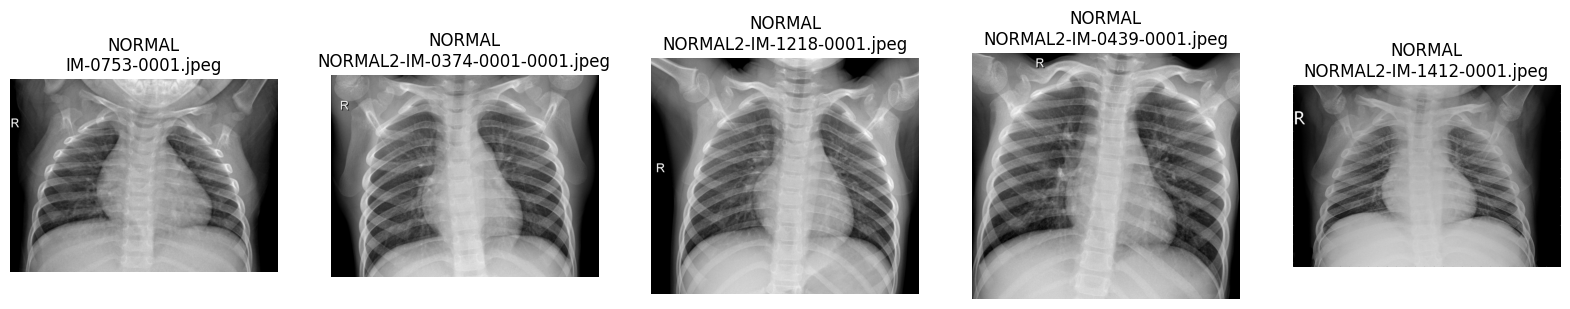

Original PNEUMONIA_VIRAL Images:


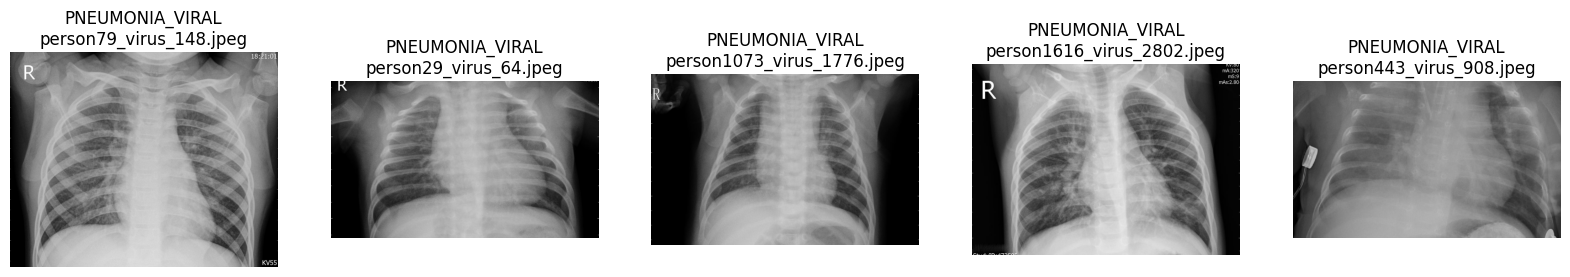

Original PNEUMONIA_BACTERIAL Images:


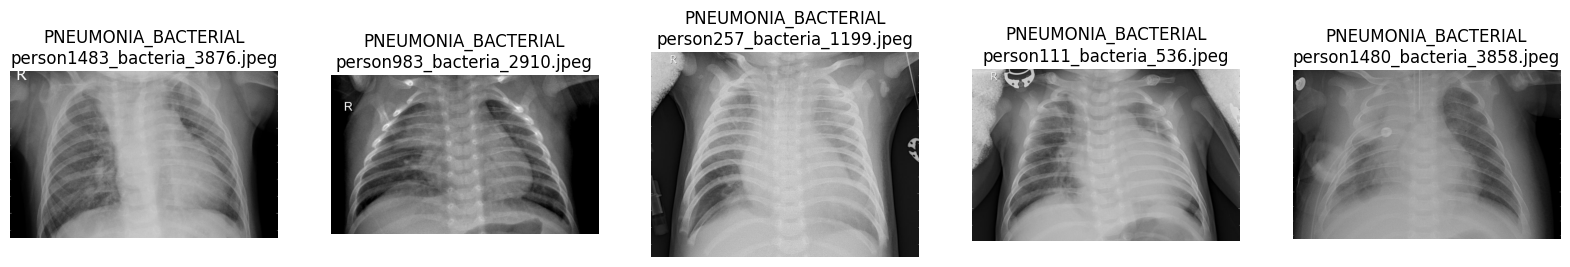

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt
import random

def plot_sample_images(folder_path, title, num_samples=5):
    images = os.listdir(folder_path)
    sample_images = random.sample(images, min(num_samples, len(images)))

    plt.figure(figsize=(20, 5))
    for i, img_name in enumerate(sample_images):
        img_path = os.path.join(folder_path, img_name)
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        plt.subplot(1, num_samples, i + 1)
        plt.imshow(img)
        plt.axis("off")
        plt.title(f"{title}\n{img_name}")

    plt.show()

# Define paths
output_normal = "/kaggle/working/NORMAL"
output_viral = "/kaggle/working/PNEUMONIA_VIRAL"
output_bacterial = "/kaggle/working/PNEUMONIA_BACTERIAL"

# Plot images from each category
print("Original NORMAL Images:")
plot_sample_images(output_normal, "NORMAL")

print("Original PNEUMONIA_VIRAL Images:")
plot_sample_images(output_viral, "PNEUMONIA_VIRAL")

print("Original PNEUMONIA_BACTERIAL Images:")
plot_sample_images(output_bacterial, "PNEUMONIA_BACTERIAL")


## Handling Class Imbalance  
### Data Augmentation for Balancing  
To ensure balanced class distribution, we applied data augmentation techniques to increase the number of samples in the underrepresented classes (**Viral Pneumonia** and **Normal**) to match **Bacterial Pneumonia** (2,780 images per class).  
After augmentation, each class contains **2,780 images**, ensuring a balanced dataset for training. This helps improve the model's learning process and reduces bias towards the majority class.  


In [ ]:

import os
import numpy as np
import cv2
import albumentations as A
from albumentations.core.composition import OneOf
from tqdm import tqdm

# Define paths
output_normal = "/kaggle/working/NORMAL"
output_viral = "/kaggle/working/PNEUMONIA_VIRAL"

# Target number of images
target_count = 2780

# Augmentation pipeline
augment = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.Rotate(limit=20, p=0.5),
    A.RandomBrightnessContrast(p=0.3),
    A.GaussianBlur(p=0.2),
    A.RandomResizedCrop(height=224, width=224, scale=(0.8, 1.0), p=0.5)
])

def augment_images(folder_path, folder_name):
    images = os.listdir(folder_path)
    current_count = len(images)

    print(f"Augmenting {folder_name}... Current: {current_count}, Target: {target_count}")

    i = 1  # Counter for new filenames
    while len(os.listdir(folder_path)) < target_count:
        img_name = np.random.choice(images)
        img_path = os.path.join(folder_path, img_name)

        # Read image
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # Apply augmentation
        augmented = augment(image=img)['image']

        # Save new image
        new_name = f"aug_{i}_{img_name}"
        cv2.imwrite(os.path.join(folder_path, new_name), cv2.cvtColor(augmented, cv2.COLOR_RGB2BGR))
        i += 1

    print(f"Completed augmentation for {folder_name}. New count: {len(os.listdir(folder_path))}")

# Perform augmentation
augment_images(output_normal, "NORMAL")
augment_images(output_viral, "PNEUMONIA_VIRAL")

print("Data augmentation completed successfully!")


Augmenting NORMAL... Current: 1583, Target: 2780
Completed augmentation for NORMAL. New count: 2780
Augmenting PNEUMONIA_VIRAL... Current: 1493, Target: 2780
Completed augmentation for PNEUMONIA_VIRAL. New count: 2780
Data augmentation completed successfully!


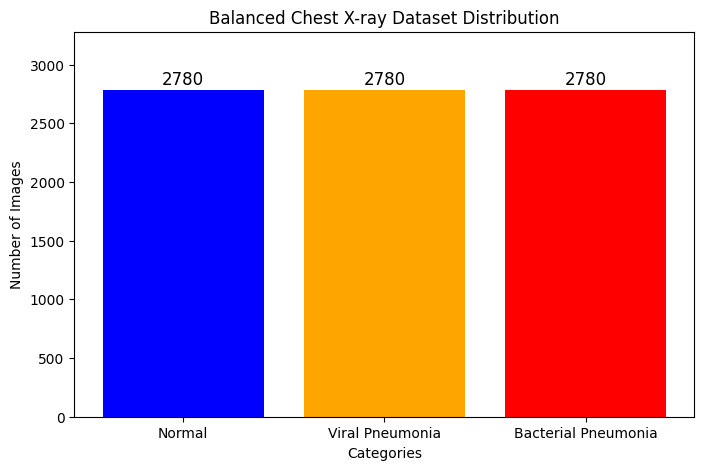

In [ ]:
import matplotlib.pyplot as plt

# Data
categories = ["Normal", "Viral Pneumonia", "Bacterial Pneumonia"]
counts = [2780, 2780, 2780]  # Updated counts after augmentation

# Plot
plt.figure(figsize=(8, 5))
plt.bar(categories, counts, color=['blue', 'orange', 'red'])
plt.xlabel("Categories")
plt.ylabel("Number of Images")
plt.title("Balanced Chest X-ray Dataset Distribution")
plt.ylim(0, max(counts) + 500)  # Adjust y-axis for better visibility

# Show values on bars
for i, count in enumerate(counts):
    plt.text(i, count + 50, str(count), ha='center', fontsize=12)

plt.show()


In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB5
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D, Input

input_shape = (224, 224, 3)
base_model = EfficientNetB5(weights='imagenet', include_top=False, input_shape=input_shape)

inputs = Input(shape=input_shape)
x = base_model(inputs, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(512, activation='relu')(x)
x = Dropout(0.3)(x)
outputs = Dense(3, activation='softmax')(x)
model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])
model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ efficientnetb5 (Functional)          │ (None, 7, 7, 2048)          │      28,513,527 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 512)                 │       1,049,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 3)                   │           1,539 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 29,564,154 (112.78 MB)

 Trainable params: 29,391,411 (112.12 MB)

 Non-trainable params: 172,743 (674.78 KB)

In [ ]:
original_folders = {
    "NORMAL": "/kaggle/working/NORMAL",
    "PNEUMONIA_BACTERIAL": "/kaggle/working/PNEUMONIA_BACTERIAL",
    "PNEUMONIA_VIRAL": "/kaggle/working/PNEUMONIA_VIRAL"
}

base_dir = "/kaggle/working/dataset"
train_dir = os.path.join(base_dir, "train")
val_dir = os.path.join(base_dir, "val")
test_dir = os.path.join(base_dir, "test")

for folder in [train_dir, val_dir, test_dir]:
    os.makedirs(folder, exist_ok=True)
    for category in original_folders.keys():
        os.makedirs(os.path.join(folder, category), exist_ok=True)

def split_and_move_images(source_folder, dest_folder, split_ratios=(0.7, 0.15, 0.15)):
    images = os.listdir(source_folder)
    random.shuffle(images)

    total_images = len(images)
    train_count = int(total_images * split_ratios[0])
    val_count = int(total_images * split_ratios[1])

    train_images = images[:train_count]
    val_images = images[train_count:train_count + val_count]
    test_images = images[train_count + val_count:]

    for img in train_images:
        shutil.copy(os.path.join(source_folder, img), os.path.join(train_dir, dest_folder, img))
    for img in val_images:
        shutil.copy(os.path.join(source_folder, img), os.path.join(val_dir, dest_folder, img))
    for img in test_images:
        shutil.copy(os.path.join(source_folder, img), os.path.join(test_dir, dest_folder, img))

for category, path in original_folders.items():
    split_and_move_images(path, category)

print("successfully split into Train, Validation, and Test sets")


successfully split into Train, Validation, and Test sets


In [ ]:
base_dir = "/kaggle/working/dataset"
sets = ["train", "val", "test"]
categories = ["NORMAL", "PNEUMONIA_BACTERIAL", "PNEUMONIA_VIRAL"]
def count_images_in_folders():
    counts = {}
    for dataset in sets:
        counts[dataset] = {}
        dataset_path = os.path.join(base_dir, dataset)
        for category in categories:
            category_path = os.path.join(dataset_path, category)
            if os.path.exists(category_path):
                counts[dataset][category] = len(os.listdir(category_path))
            else:
                counts[dataset][category] = 0
    return counts

image_counts = count_images_in_folders()

for dataset, data in image_counts.items():
    print(f"\n {dataset.upper()} SET:")
    for category, count in data.items():
        print(f"   {category}: {count} images")



 TRAIN SET:
   NORMAL: 1945 images
   PNEUMONIA_BACTERIAL: 1945 images
   PNEUMONIA_VIRAL: 1945 images

 VAL SET:
   NORMAL: 417 images
   PNEUMONIA_BACTERIAL: 417 images
   PNEUMONIA_VIRAL: 417 images

 TEST SET:
   NORMAL: 418 images
   PNEUMONIA_BACTERIAL: 418 images
   PNEUMONIA_VIRAL: 418 images


In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.applications import EfficientNetB5
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D, Input

train_dir = "/kaggle/working/dataset/train"
val_dir = "/kaggle/working/dataset/val"
test_dir = "/kaggle/working/dataset/test"

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)

val_test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)

val_generator = val_test_datagen.flow_from_directory(
    val_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)

test_generator = val_test_datagen.flow_from_directory(
    test_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

input_shape = (224, 224, 3)
base_model = EfficientNetB5(weights='imagenet', include_top=False, input_shape=input_shape)

inputs = Input(shape=input_shape)
x = base_model(inputs, training=False)  # Freeze base model
x = GlobalAveragePooling2D()(x)
x = Dense(512, activation='relu')(x)
x = Dropout(0.3)(x)
outputs = Dense(3, activation='softmax')(x)  # 3 classes

model = Model(inputs=inputs, outputs=outputs)

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6)
]

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=20,
    callbacks=callbacks
)

test_loss, test_acc = model.evaluate(test_generator)
print(f"Test Accuracy: {test_acc:.4f}")

Found 5835 images belonging to 3 classes.
Found 1251 images belonging to 3 classes.
Found 1254 images belonging to 3 classes.
Epoch 1/20


Epoch 2/20
Epoch 3/20
Epoch 4/20
Epoch 5/20
Epoch 6/20
Epoch 7/20
Epoch 8/20
Epoch 9/20
Epoch 10/20
Epoch 11/20
Epoch 12/20
Test Accuracy: 0.8708


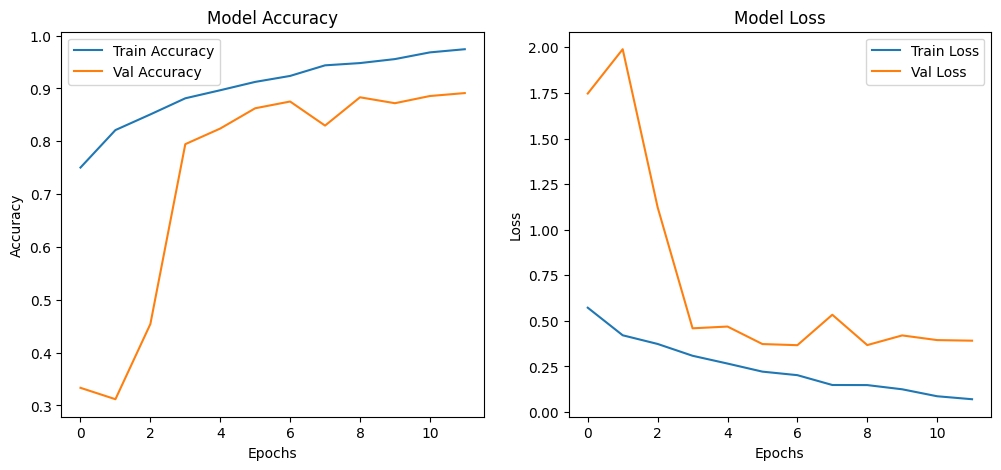

In [ ]:
def plot_history(history):
    plt.figure(figsize=(12, 5))

    # Plot Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Val Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.title('Model Accuracy')

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.title('Model Loss')

    plt.show()

# Plot training results
plot_history(history)

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
import torchvision.models as models
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, random_split
import os

dataset_path = "/kaggle/working/"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_transforms = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class CustomImageFolder(ImageFolder):
    def find_classes(self, directory):
        classes = [d.name for d in os.scandir(directory) if d.is_dir() and not d.name.startswith('.')]
        classes.sort()
        class_to_idx = {cls_name: i for i, cls_name in enumerate(classes)}
        return classes, class_to_idx

dataset = CustomImageFolder(root=dataset_path, transform=train_transforms)
train_size = int(0.8 * len(dataset))
val_size = int(0.1 * len(dataset))
test_size = len(dataset) - train_size - val_size
train_dataset, val_dataset, test_dataset = random_split(dataset, [train_size, val_size, test_size])

batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=True)

model = models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT)
num_features = model.heads.head.in_features
model.heads.head = nn.Linear(num_features, 3)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=5e-5, weight_decay=5e-3)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)

def evaluate(model, loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total

epochs_list = []
train_acc_list = []
val_acc_list = []

best_val_acc = 0
counter = 0
patience = 3
num_epochs = 15

for epoch in range(num_epochs):
    model.train()
    train_loss = 0.0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    train_loss /= len(train_loader)

    train_acc = evaluate(model, train_loader)
    val_acc = evaluate(model, val_loader)

    print(f'Epoch {epoch+1}, Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%, Val Acc: {val_acc:.2f}%')

    epochs_list.append(epoch + 1)
    train_acc_list.append(train_acc)
    val_acc_list.append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), 'best_model.pth')
        counter = 0
    else:
        counter += 1

    if counter >= patience:
        print(f'Early stopping at epoch {epoch+1}')
        break

    scheduler.step()

model.load_state_dict(torch.load('best_model.pth'))
test_acc = evaluate(model, test_loader)
print(f'Test Accuracy: {test_acc:.2f}%')


Epoch 1, Loss: 0.5416, Train Acc: 82.33%, Val Acc: 80.58%
Epoch 2, Loss: 0.4274, Train Acc: 85.64%, Val Acc: 82.25%
Epoch 3, Loss: 0.3728, Train Acc: 86.83%, Val Acc: 84.65%
Epoch 4, Loss: 0.3344, Train Acc: 87.47%, Val Acc: 83.57%
Epoch 5, Loss: 0.2903, Train Acc: 90.77%, Val Acc: 86.93%
Epoch 6, Loss: 0.2508, Train Acc: 91.85%, Val Acc: 87.41%
Epoch 7, Loss: 0.2107, Train Acc: 93.33%, Val Acc: 86.09%
Epoch 8, Loss: 0.1733, Train Acc: 94.12%, Val Acc: 85.73%
Epoch 9, Loss: 0.1394, Train Acc: 95.82%, Val Acc: 88.85%
Epoch 10, Loss: 0.1232, Train Acc: 96.01%, Val Acc: 87.77%
Epoch 11, Loss: 0.1174, Train Acc: 95.59%, Val Acc: 88.25%
Epoch 12, Loss: 0.1146, Train Acc: 96.18%, Val Acc: 88.73%
Early stopping at epoch 12


Test Accuracy: 87.65%


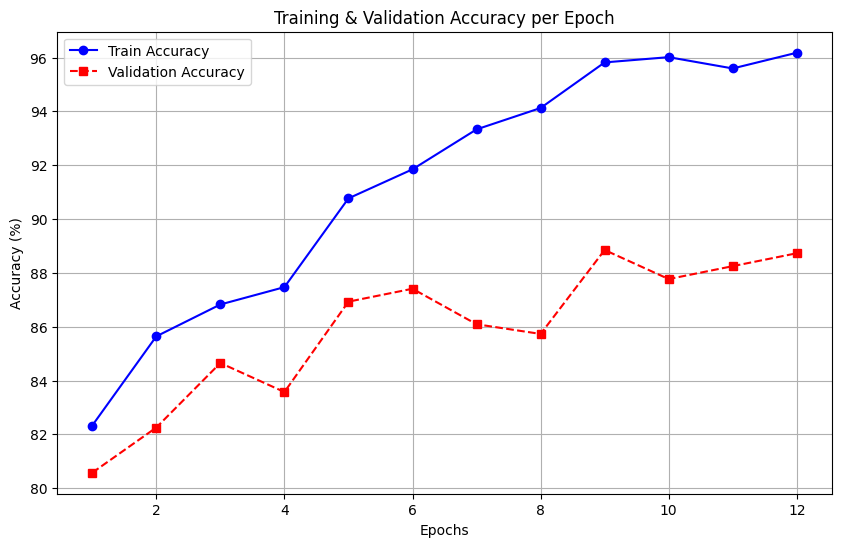

In [ ]:
# Plot Training vs Validation Accuracy
plt.figure(figsize=(10, 6))
plt.plot(epochs_list, train_acc_list, marker='o', linestyle='-', label='Train Accuracy', color='blue')
plt.plot(epochs_list, val_acc_list, marker='s', linestyle='--', label='Validation Accuracy', color='red')

plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.title('Training & Validation Accuracy per Epoch')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
#RESNET

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models

# Define device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 3)
model = model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(model.parameters(), lr=1e-5, weight_decay=1e-3)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2, verbose=True)

def evaluate(model, loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    acc = 100 * correct / total
    return acc

epochs_list = []
train_acc_list = []
val_acc_list = []

best_val_acc = 0
counter = 0
patience = 3
num_epochs = 40

for epoch in range(num_epochs):
    model.train()
    train_loss = 0.0
    correct_train = 0
    total_train = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

        _, predicted = torch.max(outputs, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    train_loss /= len(train_loader)
    train_acc = 100 * correct_train / total_train

    val_acc = evaluate(model, val_loader)
    print(f'Epoch {epoch+1}, Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%, Val Acc: {val_acc:.2f}%')
    epochs_list.append(epoch + 1)
    train_acc_list.append(train_acc)
    val_acc_list.append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), 'best_resnet_model.pth')
        counter = 0
    else:
        counter += 1

    if counter >= patience:
        print(f'Early stopping at epoch {epoch+1}')
        break

    scheduler.step(val_acc)

model.load_state_dict(torch.load('best_resnet_model.pth'))
test_acc = evaluate(model, test_loader)
print(f'Test Accuracy: {test_acc:.2f}%')


Epoch 1, Loss: 0.9402, Train Acc: 60.30%, Val Acc: 72.54%
Epoch 2, Loss: 0.6375, Train Acc: 74.72%, Val Acc: 79.14%
Epoch 3, Loss: 0.5214, Train Acc: 78.70%, Val Acc: 81.53%
Epoch 4, Loss: 0.4713, Train Acc: 80.89%, Val Acc: 82.49%
Epoch 5, Loss: 0.4403, Train Acc: 81.73%, Val Acc: 81.29%
Epoch 6, Loss: 0.4228, Train Acc: 82.72%, Val Acc: 83.69%
Epoch 7, Loss: 0.4009, Train Acc: 83.83%, Val Acc: 83.45%
Epoch 8, Loss: 0.3819, Train Acc: 84.76%, Val Acc: 84.53%
Epoch 9, Loss: 0.3688, Train Acc: 85.10%, Val Acc: 83.93%
Epoch 10, Loss: 0.3569, Train Acc: 85.63%, Val Acc: 85.73%
Epoch 11, Loss: 0.3426, Train Acc: 85.72%, Val Acc: 86.09%
Epoch 12, Loss: 0.3305, Train Acc: 86.41%, Val Acc: 85.85%
Epoch 13, Loss: 0.3235, Train Acc: 87.63%, Val Acc: 86.21%
Epoch 14, Loss: 0.3123, Train Acc: 87.59%, Val Acc: 85.37%
Epoch 15, Loss: 0.3002, Train Acc: 88.46%, Val Acc: 86.09%
Epoch 16, Loss: 0.2810, Train Acc: 89.04%, Val Acc: 85.73%
Early stopping at epoch 16


Test Accuracy: 85.13%


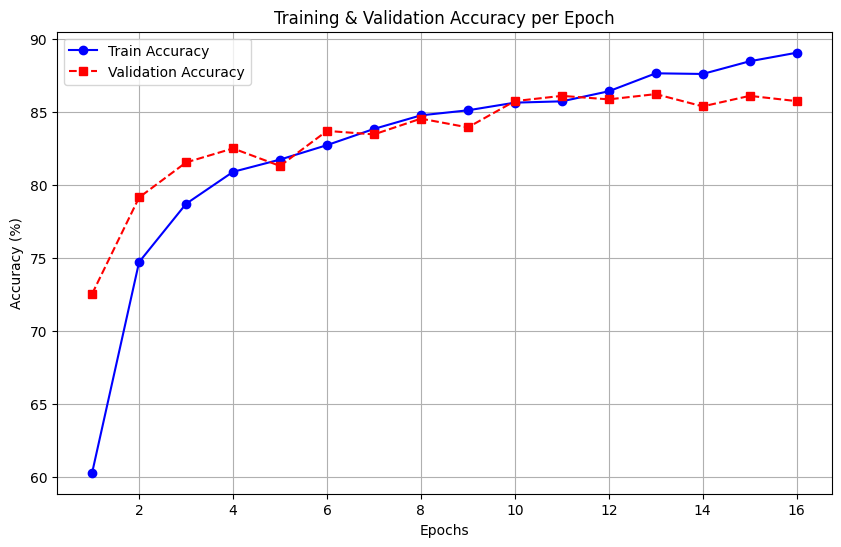

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(epochs_list, train_acc_list, marker='o', linestyle='-', label='Train Accuracy', color='blue')
plt.plot(epochs_list, val_acc_list, marker='s', linestyle='--', label='Validation Accuracy', color='red')

plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.title('Training & Validation Accuracy per Epoch')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
#Xception model

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, random_split
import timm
import os

dataset_path = "/kaggle/working/"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_transforms = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class CustomImageFolder(ImageFolder):
    def find_classes(self, directory):
        classes = [d.name for d in os.scandir(directory) if d.is_dir() and not d.name.startswith('.')]
        classes.sort()
        class_to_idx = {cls_name: i for i, cls_name in enumerate(classes)}
        return classes, class_to_idx

dataset = CustomImageFolder(root=dataset_path, transform=train_transforms)
train_size = int(0.8 * len(dataset))
val_size = int(0.1 * len(dataset))
test_size = len(dataset) - train_size - val_size
train_dataset, val_dataset, test_dataset = random_split(dataset, [train_size, val_size, test_size])

batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=True)

model = timm.create_model('xception', pretrained=True)
num_features = model.num_features
model.fc = nn.Linear(num_features, 3)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=5e-5, weight_decay=5e-3)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)

def evaluate(model, loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total

epochs_list = []
train_acc_list = []
val_acc_list = []

best_val_acc = 0
counter = 0
patience = 3
num_epochs = 15

for epoch in range(num_epochs):
    model.train()
    train_loss = 0.0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    train_loss /= len(train_loader)

    train_acc = evaluate(model, train_loader)
    val_acc = evaluate(model, val_loader)

    print(f'Epoch {epoch+1}, Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%, Val Acc: {val_acc:.2f}%')

    epochs_list.append(epoch + 1)
    train_acc_list.append(train_acc)
    val_acc_list.append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), 'best_model.pth')
        counter = 0
    else:
        counter += 1
    if counter >= patience:
        print(f'Early stopping at epoch {epoch+1}')
        break

    scheduler.step()

model.load_state_dict(torch.load('best_model.pth'))
test_acc = evaluate(model, test_loader)
print(f'Test Accuracy: {test_acc:.2f}%')

Epoch 1, Loss: 0.6098, Train Acc: 83.32%, Val Acc: 82.61%
Epoch 2, Loss: 0.4109, Train Acc: 86.69%, Val Acc: 86.33%
Epoch 3, Loss: 0.3470, Train Acc: 89.01%, Val Acc: 86.33%
Epoch 4, Loss: 0.3077, Train Acc: 90.47%, Val Acc: 87.17%
Epoch 5, Loss: 0.2778, Train Acc: 92.03%, Val Acc: 86.81%
Epoch 6, Loss: 0.2399, Train Acc: 92.45%, Val Acc: 86.93%
Epoch 7, Loss: 0.2132, Train Acc: 93.71%, Val Acc: 87.65%
Epoch 8, Loss: 0.1978, Train Acc: 94.74%, Val Acc: 88.97%
Epoch 9, Loss: 0.1904, Train Acc: 94.65%, Val Acc: 87.41%
Epoch 10, Loss: 0.1812, Train Acc: 94.83%, Val Acc: 89.81%
Epoch 11, Loss: 0.1836, Train Acc: 94.81%, Val Acc: 90.05%
Epoch 12, Loss: 0.1840, Train Acc: 94.74%, Val Acc: 88.49%
Epoch 13, Loss: 0.1898, Train Acc: 94.50%, Val Acc: 88.13%
Epoch 14, Loss: 0.1712, Train Acc: 95.41%, Val Acc: 89.45%
Early stopping at epoch 14


Test Accuracy: 87.05%


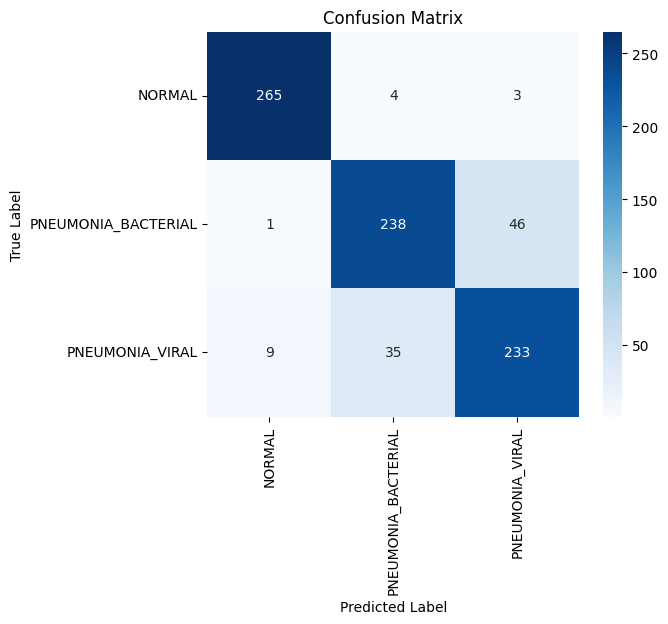

                     precision    recall  f1-score   support

             NORMAL       0.96      0.97      0.97       272
PNEUMONIA_BACTERIAL       0.86      0.84      0.85       285
    PNEUMONIA_VIRAL       0.83      0.84      0.83       277

           accuracy                           0.88       834
          macro avg       0.88      0.88      0.88       834
       weighted avg       0.88      0.88      0.88       834



In [ ]:
import torch
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

def get_predictions(model, loader):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return all_labels, all_preds

true_labels, predictions = get_predictions(model, test_loader)

cm = confusion_matrix(true_labels, predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=dataset.classes, yticklabels=dataset.classes)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

print(classification_report(true_labels, predictions, target_names=dataset.classes))
